# Lab 2

## Phase 0 — Environment and dataset
Run the setup and dataset-generation cells. Do not modify the random seed if you want results to be comparable with the instructor solution.

In [21]:
import warnings, time
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier, StackingClassifier, HistGradientBoostingClassifier
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve)
from sklearn.base import clone
SEED = 42
rng = np.random.default_rng(SEED)

In [22]:
def load_ember_forensic_dataset(n_samples=6000, seed=42):
    rng = np.random.default_rng(seed)
    y = rng.binomial(1, 0.25, n_samples)
    is_mal = y == 1
    archetype_b = is_mal & (rng.random(n_samples) < 0.35)
    archetype_a = is_mal & (~archetype_b)

    max_entropy = np.where(archetype_a, rng.normal(7.35, .40, n_samples),
                  np.where(archetype_b, rng.normal(4.30, .55, n_samples),
                           rng.normal(5.50, .95, n_samples))).clip(1, 7.99)
    import_count = np.where(archetype_a, rng.normal(14, 7, n_samples),
                   np.where(archetype_b, rng.normal(115, 35, n_samples),
                            rng.normal(95, 45, n_samples))).clip(0, 500).astype(float)
    suspicious_apis = np.where(archetype_a, rng.poisson(3.0, n_samples),
                      np.where(archetype_b, rng.poisson(11.5, n_samples),
                               rng.poisson(1.8, n_samples)))
    has_valid_sig = np.where(archetype_a, rng.binomial(1,.03,n_samples),
                    np.where(archetype_b, rng.binomial(1,.55,n_samples),
                             rng.binomial(1,.78,n_samples)))
    has_rwx = np.where(is_mal, rng.binomial(1,.52,n_samples), rng.binomial(1,.04,n_samples))
    vsize = np.where(archetype_a, rng.uniform(1.8,6.5,n_samples),
                     rng.normal(1.08,.22,n_samples)).clip(.2,15)
    res_entropy = np.where(is_mal, rng.normal(6.2,1.3,n_samples),
                           rng.normal(4.0,1.2,n_samples)).clip(0,7.99)
    urls = np.where(is_mal, rng.poisson(4.2,n_samples), rng.poisson(.6,n_samples))
    bad_time = np.where(is_mal, rng.binomial(1,.38,n_samples), rng.binomial(1,.03,n_samples))
    sections = np.where(is_mal, rng.integers(1,11,n_samples), rng.integers(3,7,n_samples))
    tls = np.where(is_mal, rng.binomial(1,.26,n_samples), rng.binomial(1,.02,n_samples))
    exports = np.where(is_mal, rng.poisson(1.0,n_samples), rng.poisson(7.5,n_samples))
    flip = rng.random(n_samples) < .04
    y_final = np.where(flip, 1-y, y)
    vt = np.where(y_final==1, rng.integers(18,68,n_samples), rng.integers(0,3,n_samples))
    df = pd.DataFrame({
      "SHA256_File_ID":[f"sha256_{i:05d}_pe" for i in range(n_samples)],
      "Max_Section_Entropy":max_entropy, "Import_Count":import_count,
      "Suspicious_API_Imports":suspicious_apis, "Has_Valid_Signature":has_valid_sig,
      "Has_RWX_Section":has_rwx, "Virtual_to_Raw_Size_Ratio":vsize,
      "Resource_Entropy":res_entropy, "Num_Embedded_URLs_IPs":urls,
      "Abnormal_Compile_Timestamp":bad_time, "Num_Sections":sections,
      "Has_TLS_Callback":tls, "Export_Count":exports,
      "VT_PostScan_Detections":vt, "Is_Malware":y_final
    })
    df.loc[rng.random(n_samples)<.05, "Resource_Entropy"] = np.nan
    df.loc[rng.random(n_samples)<.04, "Import_Count"] = np.nan
    df.loc[rng.random(n_samples)<.01, "Virtual_to_Raw_Size_Ratio"] = 99999.0
    return df
df_pe = load_ember_forensic_dataset()
print(df_pe.shape, "Malware prevalence:", round(df_pe.Is_Malware.mean(),3))
display(df_pe.head())

(6000, 15) Malware prevalence: 0.268


,SHA256_File_ID,Max_Section_Entropy,Import_Count,Suspicious_API_Imports,Has_Valid_Signature,Has_RWX_Section,Virtual_to_Raw_Size_Ratio,Resource_Entropy,Num_Embedded_URLs_IPs,Abnormal_Compile_Timestamp,Num_Sections,Has_TLS_Callback,Export_Count,VT_PostScan_Detections,Is_Malware
0,sha256_00000_pe,7.461459,25.464072,2,0,1,5.158277,7.081268,3,0,2,0,2,45,1
1,sha256_00001_pe,5.872605,104.603878,2,1,0,0.871620,4.123092,0,0,4,0,6,2,0
2,sha256_00002_pe,7.188000,13.758941,4,0,1,3.447490,4.776004,2,0,9,0,2,36,1
3,sha256_00003_pe,6.330688,96.169063,2,1,0,1.027833,4.654296,3,0,4,0,8,0,0
4,sha256_00004_pe,5.211025,97.108682,3,0,0,1.031020,4.442302,0,0,5,0,2,1,0


## Phase 1 — Forensic data audit and problem formulation


In [23]:
# TASK 1: audit data quality.
print("--- Dataset Dimensions ---")
print(df_pe.shape)

print("\n--- Class Balance ---")
print(df_pe["Is_Malware"].value_counts(normalize=True))   #0 = Benign (safe file)   - 1 = Malware (malicious file).
#Counts how many times each value appears.
print("\n--- Missing Values Count ---")
print(df_pe.isnull().sum()[df_pe.isnull().sum() > 0])

print("\n--- Duplicate Rows ---")
print("Duplicate rows count:", df_pe.duplicated().sum())

print("\n--- Summary Statistics ---")
display(df_pe.describe())

--- Dataset Dimensions ---
(6000, 15)

--- Class Balance ---
Is_Malware
0    0.7315
1    0.2685
Name: proportion, dtype: float64

--- Missing Values Count ---
Import_Count        229
Resource_Entropy    289
dtype: int64

--- Duplicate Rows ---
Duplicate rows count: 0

--- Summary Statistics ---


,Max_Section_Entropy,Import_Count,Suspicious_API_Imports,Has_Valid_Signature,Has_RWX_Section,Virtual_to_Raw_Size_Ratio,Resource_Entropy,Num_Embedded_URLs_IPs,Abnormal_Compile_Timestamp,Num_Sections,Has_TLS_Callback,Export_Count,VT_PostScan_Detections,Is_Malware
count,6000.000000,5771.000000,6000.000000,6000.000000,6000.000000,6000.000000,5711.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000
mean,5.709010,83.386866,2.800167,0.630833,0.149833,984.890348,4.535160,1.468333,0.114833,4.758667,0.079167,5.907500,12.080833,0.268500
std,1.170152,50.301130,3.094430,0.482619,0.356938,9868.008483,1.501097,1.951742,0.318847,1.784551,0.270021,3.708401,19.753109,0.443216
min,2.146111,0.000000,0.000000,0.000000,0.000000,0.367195,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,4.821742,41.184528,1.000000,0.000000,0.000000,0.955570,3.483114,0.000000,0.000000,3.000000,0.000000,3.000000,0.000000,0.000000
50%,5.639862,85.663796,2.000000,1.000000,0.000000,1.129836,4.432941,1.000000,0.000000,5.000000,0.000000,6.000000,2.000000,0.000000
75%,6.604762,120.408591,3.000000,1.000000,0.000000,1.366755,5.517712,2.000000,0.000000,6.000000,0.000000,9.000000,21.000000,1.000000
max,7.990000,320.325585,24.000000,1.000000,1.000000,99999.000000,7.990000,11.000000,1.000000,10.000000,1.000000,18.000000,67.000000,1.000000


Number of rows with invalid parser value (99999.0) in Virtual_to_Raw_Size_Ratio: 59


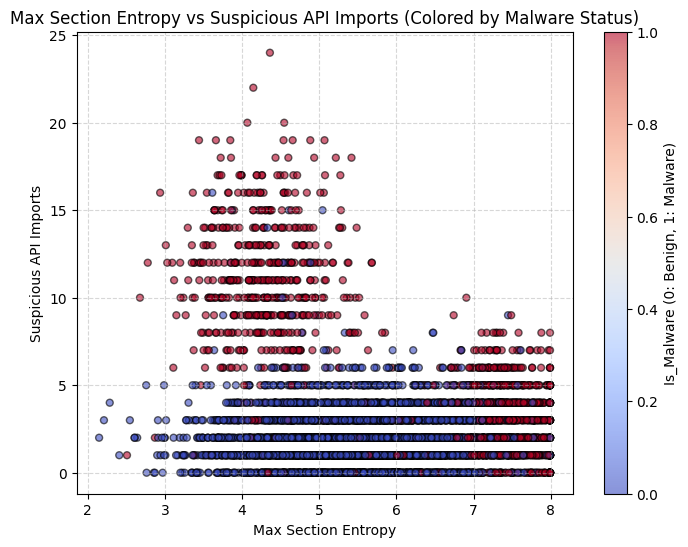

In [24]:
# TASK 2: inspect the suspicious ratio values and feature distributions.
invalid_ratio_count = (df_pe["Virtual_to_Raw_Size_Ratio"] == 99999.0).sum()
print(f"Number of rows with invalid parser value (99999.0) in Virtual_to_Raw_Size_Ratio: {invalid_ratio_count}")

# Visualize Max_Section_Entropy vs Suspicious_API_Imports
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    df_pe["Max_Section_Entropy"], 
    df_pe["Suspicious_API_Imports"], 
    c=df_pe["Is_Malware"], 
    cmap="coolwarm", 
    alpha=0.6, 
    edgecolors="k", s=25
)
plt.colorbar(scatter, label="Is_Malware (0: Benign, 1: Malware)")
plt.xlabel("Max Section Entropy")
plt.ylabel("Suspicious API Imports")
plt.title("Max Section Entropy vs Suspicious API Imports (Colored by Malware Status)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [25]:
# TASK 3: define the target and clean feature matrix.
# Drop identifiers, post-scan features, and the target from X
X = df_pe.drop(columns=["SHA256_File_ID", "VT_PostScan_Detections", "Is_Malware"]) #columns to remove.
y = df_pe["Is_Malware"]

# Replace impossible parser values (99999.0) with NaN so they can be imputed properly
X["Virtual_to_Raw_Size_Ratio"] = X["Virtual_to_Raw_Size_Ratio"].replace(99999.0, np.nan)

print("Feature matrix shape (X):", X.shape)
print("Target vector shape (y):", y.shape)
print("Count of NaNs in Virtual_to_Raw_Size_Ratio after cleaning:", X["Virtual_to_Raw_Size_Ratio"].isna().sum())

Feature matrix shape (X): (6000, 12)
Target vector shape (y): (6000,)
Count of NaNs in Virtual_to_Raw_Size_Ratio after cleaning: 59


## Phase 2 — Design a leakage-safe evaluation protocol

In [26]:
from sklearn.ensemble import HistGradientBoostingClassifier

# Stratified 80/20 development/test split (Lockbox test set)
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

print(f"X_dev shape: {X_dev.shape}, X_test shape: {X_test.shape}")

# Define Stratified 5-Fold Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Define Candidate Pipelines
# Note: RobustScaler is used for Logistic Regression (linear model sensitive to feature scales).
# Tree-based models (Decision Tree, Random Forest, HistGradientBoosting) are scale-invariant, so scaling is omitted.
pipelines = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", RobustScaler()),
        ("clf", LogisticRegression(random_state=SEED, max_iter=1000))
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("clf", DecisionTreeClassifier(random_state=SEED))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("clf", RandomForestClassifier(random_state=SEED, n_estimators=100))
    ]),
    "HistGradientBoosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("clf", HistGradientBoostingClassifier(random_state=SEED))
    ])
}

# Evaluate models using cross_validate
scoring = {"f1": "f1", "precision": "precision", "recall": "recall", "pr_auc": "average_precision"}
results_summary = []

for name, pipeline in pipelines.items():
    start_time = time.time()
    cv_results = cross_validate(pipeline, X_dev, y_dev, cv=cv, scoring=scoring, n_jobs=-1, return_train_score=True)
    fit_time = time.time() - start_time
    
    results_summary.append({
        "Model": name,
        "Train F1 (Mean)": np.mean(cv_results["train_f1"]),
        "Val F1 (Mean)": np.mean(cv_results["test_f1"]),
        "Val PR-AUC (Mean)": np.mean(cv_results["test_pr_auc"]),
        "Fit Time (s)": round(fit_time, 2)
    })

df_results = pd.DataFrame(results_summary)
print("\n--- Model Benchmark Results ---")
display(df_results)

X_dev shape: (4800, 12), X_test shape: (1200, 12)

--- Model Benchmark Results ---


,Model,Train F1 (Mean),Val F1 (Mean),Val PR-AUC (Mean),Fit Time (s)
0,Logistic Regression,0.923122,0.923810,0.907990,1.93
1,Decision Tree,1.000000,0.830111,0.732977,0.22
2,Random Forest,0.999903,0.924065,0.903551,2.41
3,HistGradientBoosting,0.980016,0.923183,0.907987,1.27


In [27]:
# Fit selected models on full X_dev
for name, pipeline in pipelines.items():
    pipeline.fit(X_dev, y_dev)

# Measure prediction latency (milliseconds per 1,000 files)
n_runs = 100
sample_batch = X_test.iloc[:1000]

print("--- Prediction Latency (ms per 1,000 files) ---")
for name, pipeline in pipelines.items():
    start_time = time.time()
    for _ in range(n_runs):
        _ = pipeline.predict(sample_batch)
    total_time = time.time() - start_time
    ms_per_1000 = (total_time / n_runs) * 1000
    print(f"{name}: {ms_per_1000:.2f} ms")

--- Prediction Latency (ms per 1,000 files) ---
Logistic Regression: 1.91 ms
Decision Tree: 1.73 ms
Random Forest: 18.99 ms
HistGradientBoosting: 8.79 ms


# Phase 3 — Error forensics: investigate a real disagreement

In [28]:
# Fit Logistic Regression and Random Forest on X_dev
lr_pipe = pipelines["Logistic Regression"].fit(X_dev, y_dev)
rf_pipe = pipelines["Random Forest"].fit(X_dev, y_dev)

# Predict probabilities on X_test
lr_probs = lr_pipe.predict_proba(X_test)[:, 1]   #1 malwer
rf_probs = rf_pipe.predict_proba(X_test)[:, 1]

# Find instances where LR predicts benign (< 0.50) and RF predicts malware (>= 0.50)
disagreement_indices = np.where((lr_probs < 0.50) & (rf_probs >= 0.50))[0]

if len(disagreement_indices) > 0:
    chosen_idx = disagreement_indices[0]
    test_instance_id = X_test.index[chosen_idx]
    
    print(f"Found disagreement at test index position: {chosen_idx} (Original Index: {test_instance_id})")
    print(f"Ground Truth Label (Is_Malware): {y_test.iloc[chosen_idx]}")
    print(f"Logistic Regression Probability: {lr_probs[chosen_idx]:.4f} (Pred: {int(lr_probs[chosen_idx] >= 0.5)})")
    print(f"Random Forest Probability: {rf_probs[chosen_idx]:.4f} (Pred: {int(rf_probs[chosen_idx] >= 0.5)})")
    
    print("\nFeature Values for this instance:")
    display(X_test.iloc[chosen_idx])
else:
    print("No direct disagreement found with these exact thresholds, reviewing alternative thresholds...")

Found disagreement at test index position: 105 (Original Index: 5787)
Ground Truth Label (Is_Malware): 1
Logistic Regression Probability: 0.3044 (Pred: 0)
Random Forest Probability: 0.5300 (Pred: 1)

Feature Values for this instance:


Max_Section_Entropy             4.603163
Import_Count                  116.690922
Suspicious_API_Imports          3.000000
Has_Valid_Signature             0.000000
Has_RWX_Section                 0.000000
Virtual_to_Raw_Size_Ratio       0.944756
Resource_Entropy                     NaN
Num_Embedded_URLs_IPs           2.000000
Abnormal_Compile_Timestamp      0.000000
Num_Sections                    9.000000
Has_TLS_Callback                0.000000
Export_Count                    1.000000
Name: 5787, dtype: float64

Background dataset has 4800 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=4800 when initializing the masker.
100%|===================| 2391/2400 [00:49<00:00]        

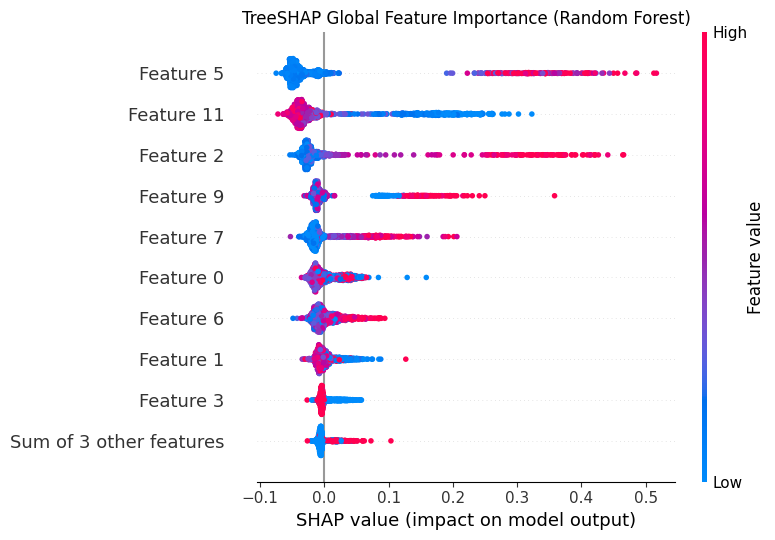

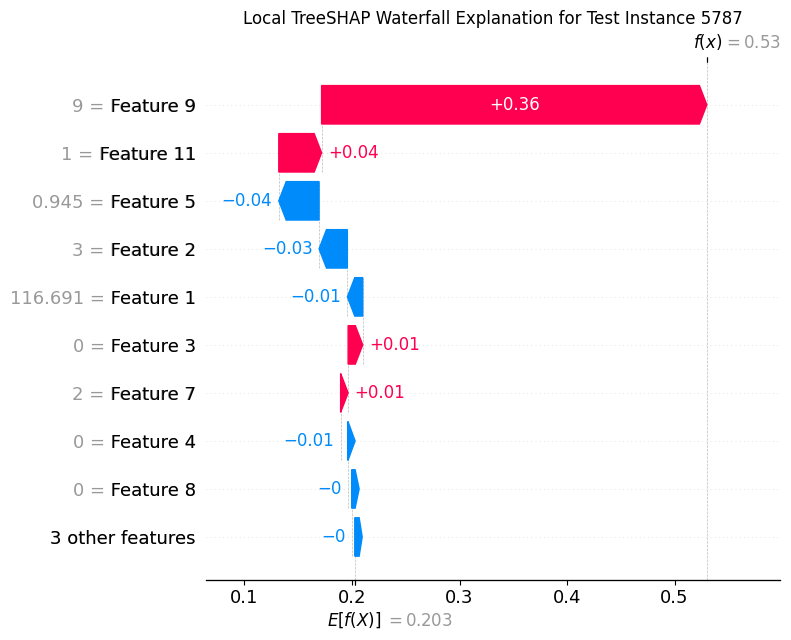

In [29]:

# Ensure shap package is available
import shap
import matplotlib.pyplot as plt

# Use TreeExplainer on the Random Forest classifier component
rf_model = rf_pipe.named_steps["clf"]
imputer = rf_pipe.named_steps["imputer"]

X_dev_imputed = imputer.transform(X_dev)
X_test_imputed = imputer.transform(X_test)

# Initialize SHAP Explainer
explainer = shap.TreeExplainer(rf_model, X_dev_imputed)
shap_values = explainer(X_test_imputed)  #calculate the contribution of each feature for every file in your test dataset.

# Select Class 1 for binary classification
if len(shap_values.values.shape) == 3:
    shap_values_plot = shap_values[:, :, 1]
else:
    shap_values_plot = shap_values

# 1. Global Beeswarm Plot
shap.plots.beeswarm(
    shap_values_plot,
    max_display=10,
    show=False
)
plt.title("TreeSHAP Global Feature Importance (Random Forest)")
plt.tight_layout()
plt.show()

# 2. Local Waterfall Plot for the disagreed instance
if len(disagreement_indices) > 0:
    shap.plots.waterfall(
        shap_values_plot[chosen_idx],
        show=False
    )
    plt.title(
        f"Local TreeSHAP Waterfall Explanation "
        f"for Test Instance {test_instance_id}"
    )
    plt.tight_layout()
    plt.show()


# Phase 4 — Translate model scores into a SOC decision

Optimal Decision Threshold (optimized on OOF dev data): 0.396
Minimum OOF Estimated Cost: $72,650.00

--- Lockbox Test Set Evaluation (Frozen Threshold) ---
Test Cost: $17,725.00
Test Precision: 0.9696
Test Recall: 0.8913
Test F1-Score: 0.9288
Test False Positives (FP): 9
Test False Negatives (FN): 35


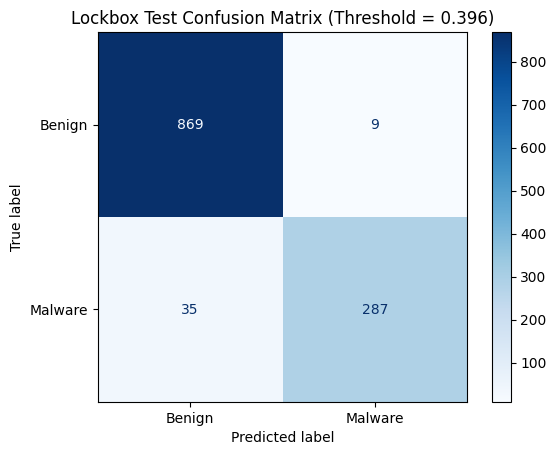

In [30]:
# Generate out-of-fold (OOF) probabilities for cross-validation evaluation
from sklearn.model_selection import cross_val_predict

selected_pipeline = pipelines["Random Forest"] # Or HistGradientBoosting based on performance

# Generate OOF probabilities securely using cross_val_predict
oof_probs = cross_val_predict(selected_pipeline, X_dev, y_dev, cv=cv, method="predict_proba")[:, 1]

COST_FP = 25
COST_FN = 500

thresholds = np.linspace(0.01, 0.99, 100)
best_threshold = 0.5
min_total_cost = float("inf")

# Optimize threshold on OOF development predictions only
for tau in thresholds:
    preds = (oof_probs >= tau).astype(int)
    cm = confusion_matrix(y_dev, preds)
    # confusion_matrix structure: [[TN, FP], [FN, TP]]
    fp = cm[0, 1]
    fn = cm[1, 0]
    total_cost = (COST_FP * fp) + (COST_FN * fn)
    
    if total_cost < min_total_cost:
        min_total_cost = total_cost
        best_threshold = tau

print(f"Optimal Decision Threshold (optimized on OOF dev data): {best_threshold:.3f}")
print(f"Minimum OOF Estimated Cost: ${min_total_cost:,.2f}")

# Freeze threshold and evaluate once on the Lockbox Test Set (X_test, y_test)
selected_pipeline.fit(X_dev, y_dev) # Fit on full development set
test_probs = selected_pipeline.predict_proba(X_test)[:, 1]
test_preds = (test_probs >= best_threshold).astype(int)

test_cm = confusion_matrix(y_test, test_preds)
test_fp = test_cm[0, 1]
test_fn = test_cm[1, 0]
test_tp = test_cm[1, 1]
test_tn = test_cm[0, 0]

test_total_cost = (COST_FP * test_fp) + (COST_FN * test_fn)
test_precision = precision_score(y_test, test_preds, zero_division=0)
test_recall = recall_score(y_test, test_preds, zero_division=0)
test_f1 = f1_score(y_test, test_preds, zero_division=0)

print("\n--- Lockbox Test Set Evaluation (Frozen Threshold) ---")
print(f"Test Cost: ${test_total_cost:,.2f}")
print(f"Test Precision: {test_precision:.4f}")
print(f"Test Recall: {test_recall:.4f}")
print(f"Test F1-Score: {test_f1:.4f}")
print(f"Test False Positives (FP): {test_fp}")
print(f"Test False Negatives (FN): {test_fn}")

# Display Confusion Matrix
disp = ConfusionMatrixDisplay(confusion_matrix=test_cm, display_labels=["Benign", "Malware"])
disp.plot(cmap=plt.cm.Blues)
plt.title(f"Lockbox Test Confusion Matrix (Threshold = {best_threshold:.3f})")
plt.show()

In [31]:
# Re-optimize threshold under high FP cost ($2,000 vs $500 FN)
COST_FP_HIGH = 2000
best_threshold_high = 0.5
min_total_cost_high = float("inf")

for tau in thresholds:
    preds = (oof_probs >= tau).astype(int)
    cm = confusion_matrix(y_dev, preds)
    fp = cm[0, 1]
    fn = cm[1, 0]
    total_cost = (COST_FP_HIGH * fp) + (COST_FN * fn)
    
    if total_cost < min_total_cost_high:
        min_total_cost_high = total_cost
        best_threshold_high = tau

print(f"Optimal Threshold under High FP Cost ($2,000): {best_threshold_high:.3f}")
print("Why it changes: When false positives become significantly more expensive (blocking legitimate software/payments), the model must shift its decision threshold upward to be much more conservative, reducing false alarms at the expense of missing a few more threats.")

Optimal Threshold under High FP Cost ($2,000): 0.713
Why it changes: When false positives become significantly more expensive (blocking legitimate software/payments), the model must shift its decision threshold upward to be much more conservative, reducing false alarms at the expense of missing a few more threats.


github:  https://github.com/MOha1212123/TP2-IA
kaggle 